# Patient Comparison

Side-by-side comparison of two patients: ambulatory glucose profile (AGP), a 7-day glucose trace with the classified episodes (SLH / LLH), and a metrics table.

Equivalent script: `python3 -m scripts.patient_comparison`.

**Usage** — from the repository root, point the notebook at a data folder and open it
(the 4-patient synthetic sample is enough: `make sample_data_run`):

```bash
CGM_DATA_ROOT=$PWD/sample_data jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the **synthetic sample dataset** (`make sample_data`: fake patients A001–A004, simulated glucose, time expressed relative to an arbitrary t = 0). It contains **no real patient data**, and the numbers and figures are not expected to match the manuscript.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from src.config import TIME_COL, GLUCOSE_COL, PATIENT_ID_COL, CLASSIFICATION_SLH, CLASSIFICATION_LLH, COL_EPISODE_CLASSIFICATION
from src.preprocessing.load_data import load_patient_window, prepare_valid_data
from src.preprocessing.timestep import detect_dominant_sampling_interval
from src.episodes.load_episodes import load_patient_episodes, load_episode_summary
from src.agp.compute_agp import compute_agp_profile
from src.visualization.style import apply_publication_style
from src.visualization.agp_plot import plot_agp_panel, plot_metrics_table, plot_7day_trace, add_panel_label

%matplotlib inline

## 2. Choose the two patients

By default the patients with the **fewest** and the **most** SLH episodes are compared; set `PATIENT_A` / `PATIENT_B` to any two IDs to compare others.

In [2]:
summary = load_episode_summary().sort_values("n_SLH")

PATIENT_A = summary[PATIENT_ID_COL].iloc[0]    # fewest SLH episodes
PATIENT_B = summary[PATIENT_ID_COL].iloc[-1]   # most SLH episodes

summary[summary[PATIENT_ID_COL].isin([PATIENT_A, PATIENT_B])]

  Loaded 4 patients from episodes summary


,patient_id,n_SLH,n_LLH
3,A004,10,51
2,A003,181,10


## 3. Per-patient data

For each patient: the valid CGM window, the classified episodes, the AGP and summary metrics.

In [3]:
def cgm_metrics(df):
    """Standard CGM metrics (glucose in mg/dL, ranges in % of readings)."""
    g = df[GLUCOSE_COL]
    return {
        "Mean": round(g.mean(), 1),
        "Median": round(g.median(), 1),
        "SD": round(g.std(), 1),
        "CV": round(g.std() / g.mean() * 100, 1),
        "TIR70-180": round(((g >= 70) & (g <= 180)).mean() * 100, 1),
        "TAR>180": round((g > 180).mean() * 100, 1),
        "TAR>250": round((g > 250).mean() * 100, 1),
        "TBR<70": round((g < 70).mean() * 100, 1),
    }


def patient_data(patient_id):
    valid = prepare_valid_data(load_patient_window(patient_id))
    episodes = load_patient_episodes(patient_id)

    resolution = detect_dominant_sampling_interval(valid)
    counts = episodes[COL_EPISODE_CLASSIFICATION].value_counts()

    return {
        "valid_data": valid,
        "episodes": episodes,
        "resolution": resolution,
        "agp": compute_agp_profile(valid, resolution),
        "metrics": cgm_metrics(valid),
        "counts": {CLASSIFICATION_SLH: int(counts.get(CLASSIFICATION_SLH, 0)),
                   CLASSIFICATION_LLH: int(counts.get(CLASSIFICATION_LLH, 0))},
    }


data_a, data_b = patient_data(PATIENT_A), patient_data(PATIENT_B)

pd.DataFrame({PATIENT_A: {**data_a["metrics"], **{f"n_{k}": v for k, v in data_a["counts"].items()}},
              PATIENT_B: {**data_b["metrics"], **{f"n_{k}": v for k, v in data_b["counts"].items()}}})

,A004,A003
Mean,146.7,126.8
Median,143.0,118.0
SD,15.7,28.2
CV,10.7,22.3
TIR70-180,95.9,91.7
TAR>180,4.1,8.3
TAR>250,0.0,0.0
TBR<70,0.0,0.0
n_SLH,10.0,181.0
n_LLH,51.0,10.0


## 4. Comparison figure

Legends and threshold annotations are drawn on the right-hand column only, to avoid repeating them.

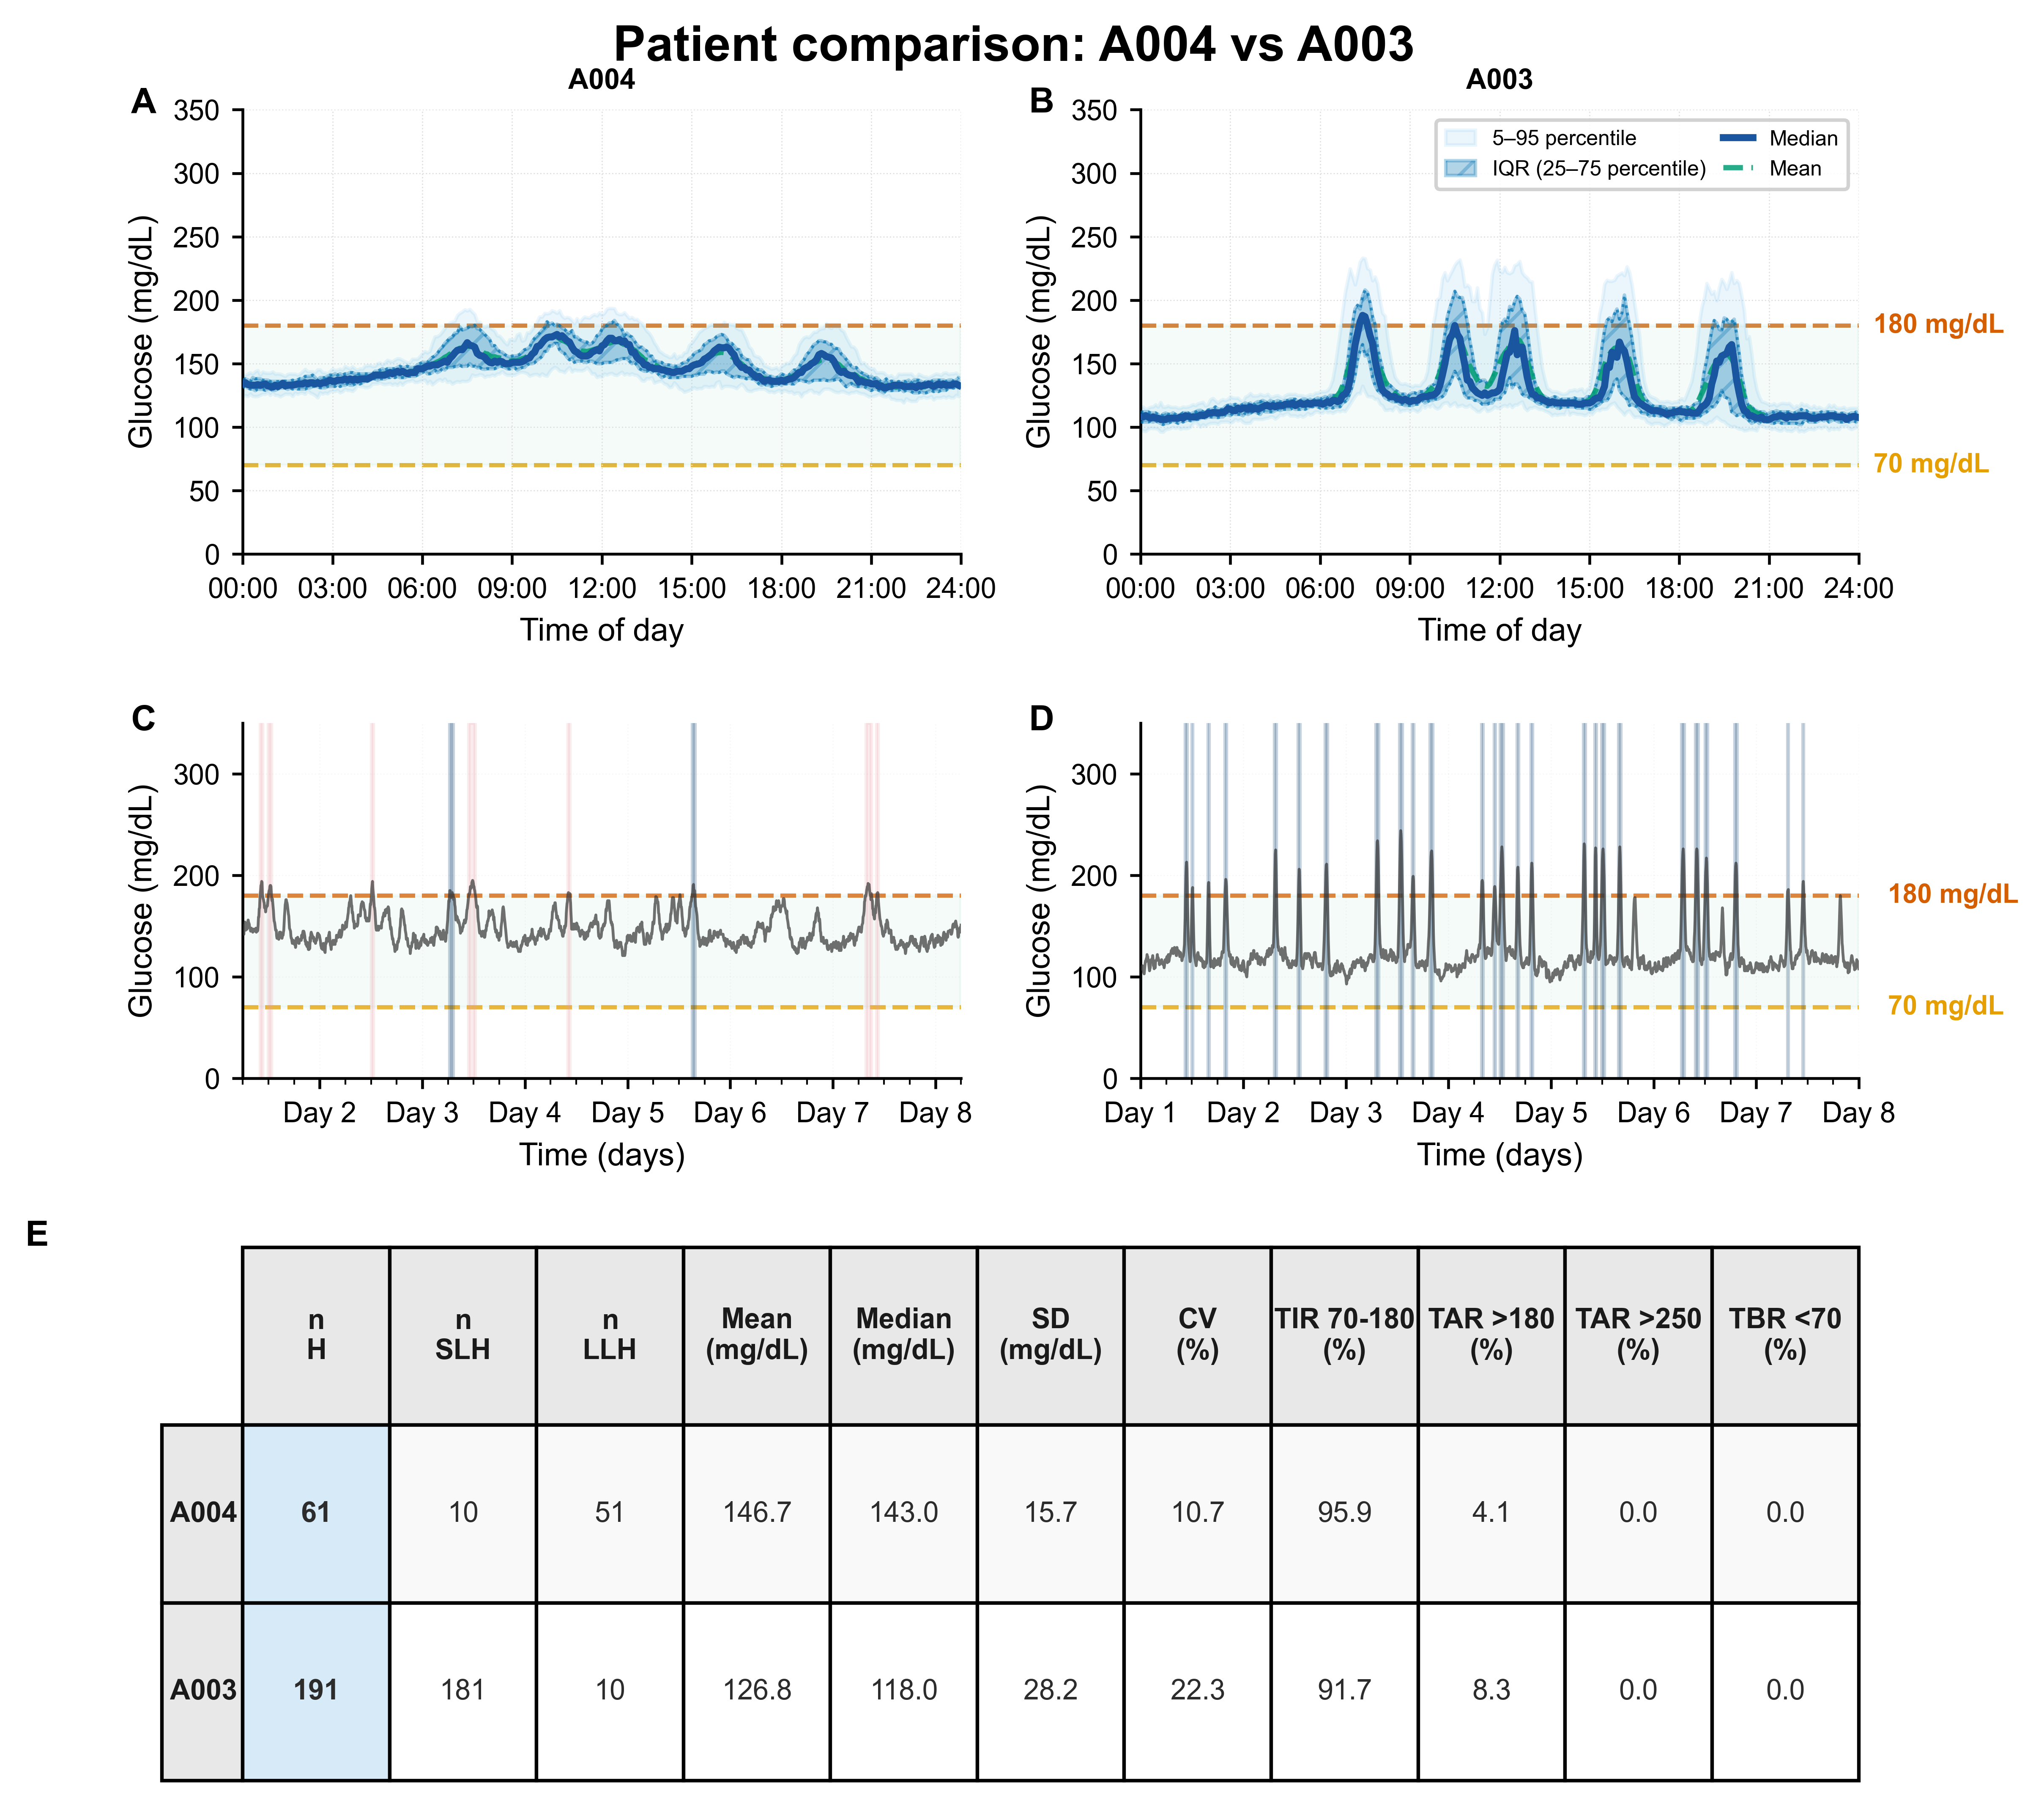

In [4]:
apply_publication_style()
fig = plt.figure(figsize=(7.24, 7.4))
gs = GridSpec(3, 2, figure=fig, height_ratios=[1, 0.8, 1.2], hspace=0.38, wspace=0.25,
              left=0.08, right=0.96, top=0.94, bottom=0.05)

ax_agp_a, ax_agp_b = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_tr_a, ax_tr_b = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
ax_table = fig.add_subplot(gs[2, :])

plot_agp_panel(ax_agp_a, data_a["agp"], PATIENT_A, show_legend=False, show_threshold_annotations=False)
plot_agp_panel(ax_agp_b, data_b["agp"], PATIENT_B, show_legend=True, show_threshold_annotations=True)

plot_7day_trace(ax_tr_a, data_a["valid_data"], data_a["episodes"], PATIENT_A, show_threshold_annotations=False)
plot_7day_trace(ax_tr_b, data_b["valid_data"], data_b["episodes"], PATIENT_B, show_threshold_annotations=True)

plot_metrics_table(ax_table, data_a["metrics"], data_b["metrics"], data_a["counts"], data_b["counts"],
                   PATIENT_A, PATIENT_B, include_classification=True)

for ax, letter in zip([ax_agp_a, ax_agp_b, ax_tr_a, ax_tr_b, ax_table], "ABCDE"):
    add_panel_label(ax, letter)
fig.suptitle(f"Patient comparison: {PATIENT_A} vs {PATIENT_B}", fontsize=14, fontweight="bold", y=0.985)
plt.show()